# Netflix Customer Churn Analysis

Notebook ini mencakup data loading, cleaning, EDA, feature engineering, train-test split, modeling, dan evaluasi MSE, MAE, R² serta metrik klasifikasi.

**Catatan:** `churned` adalah target biner, jadi ini merupakan masalah klasifikasi. MSE, MAE, dan R² dihitung terhadap probabilitas prediksi; accuracy, precision, recall, dan F1-score juga disertakan.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan file CSV berada di folder yang sama dengan notebook.
df = pd.read_csv("netflix_customer_churn.csv")

print("Ukuran dataset:", df.shape)
display(df.head())
df.info()

Ukuran dataset: (5000, 14)


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 547.0

## 1. Data Cleaning

In [3]:
# Mengecek missing value dan duplikasi
print("Missing value per kolom:")
display(df.isnull().sum())

print("Jumlah baris duplikat:", df.duplicated().sum())

# Menghapus baris duplikat
df = df.drop_duplicates().copy()

# Hapus kolom ID jika tersedia karena biasanya bukan fitur prediksi
if "customer_id" in df.columns:
    df = df.drop(columns=["customer_id"])

# Pastikan target tersedia
if "churned" not in df.columns:
    raise ValueError("Kolom target 'churned' tidak ditemukan. Periksa nama kolom pada CSV.")

print("Ukuran setelah cleaning:", df.shape)
display(df.isnull().sum())

Missing value per kolom:


customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

Jumlah baris duplikat: 0
Ukuran setelah cleaning: (5000, 13)


age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

## 2. EDA (Exploratory Data Analysis)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,5000.0,NaN,NaN,NaN,43.8474,15.501128,18.0,30.0,44.0,58.0,70.0
gender,5000,3,Female,1711,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subscription_type,5000,3,Premium,1693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
watch_hours,5000.0,NaN,NaN,NaN,11.64945,12.014654,0.01,3.3375,8.0,16.03,110.4
last_login_days,5000.0,NaN,NaN,NaN,30.0898,17.536078,0.0,15.0,30.0,45.0,60.0
region,5000,6,South America,873,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device,5000,5,Tablet,1048,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_fee,5000.0,NaN,NaN,NaN,13.6834,3.692062,8.99,8.99,13.99,17.99,17.99
churned,5000.0,NaN,NaN,NaN,0.503,0.500041,0.0,0.0,1.0,1.0,1.0
payment_method,5000,5,Debit Card,1030,NaN,NaN,NaN,NaN,NaN,NaN,NaN


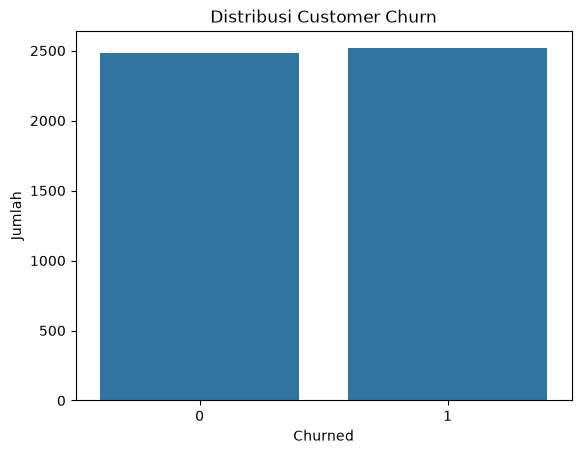

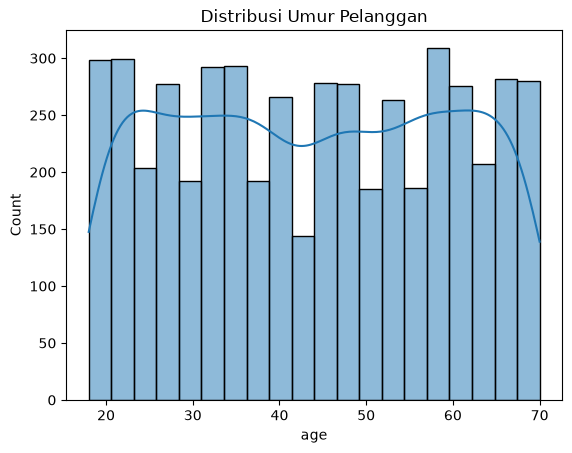

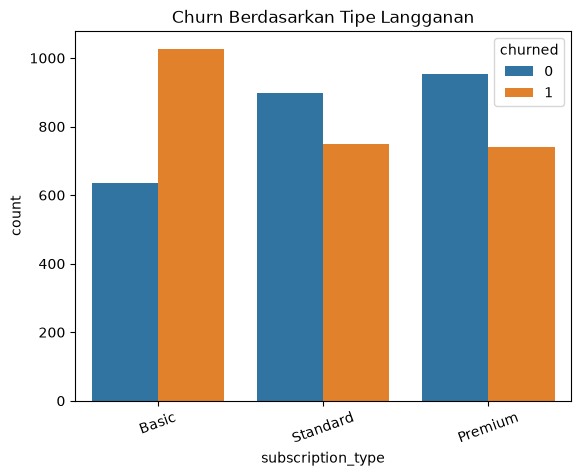

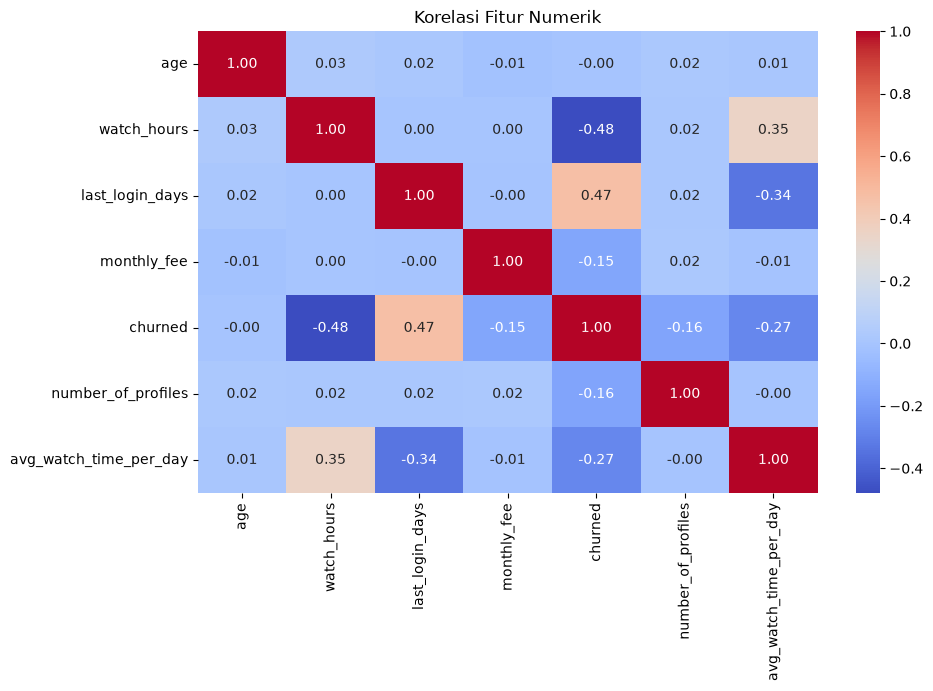

In [4]:
# Statistik deskriptif
display(df.describe(include="all").T)

# Distribusi target churn
sns.countplot(data=df, x="churned")
plt.title("Distribusi Customer Churn")
plt.xlabel("Churned")
plt.ylabel("Jumlah")
plt.show()

# Histogram untuk kolom umur, jika tersedia
if "age" in df.columns:
    sns.histplot(data=df, x="age", bins=20, kde=True)
    plt.title("Distribusi Umur Pelanggan")
    plt.show()

# Churn berdasarkan tipe langganan, jika kolom tersedia
if "subscription_type" in df.columns:
    sns.countplot(data=df, x="subscription_type", hue="churned")
    plt.title("Churn Berdasarkan Tipe Langganan")
    plt.xticks(rotation=20)
    plt.show()

# Korelasi fitur numerik
numeric_df = df.select_dtypes(include="number")
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 6))
    sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Korelasi Fitur Numerik")
    plt.show()

## 3. Feature Engineering dan Preprocessing

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

X = df.drop(columns=["churned"])
y = df["churned"]

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Fitur numerik:", numeric_features)
print("Fitur kategori:", categorical_features)

ModuleNotFoundError: No module named 'sklearn'

## 4. Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data training:", X_train.shape)
print("Data testing:", X_test.shape)

## 5. Modeling

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Model berhasil dilatih.")

## 6. Evaluasi Model: MSE, MAE, R² dan Metrik Klasifikasi

In [ ]:
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# MSE, MAE, dan R² dihitung dari probabilitas churn
mse = mean_squared_error(y_test, y_prob)
mae = mean_absolute_error(y_test, y_prob)
r2 = r2_score(y_test, y_prob)

print("MSE :", round(mse, 4))
print("MAE :", round(mae, 4))
print("R²  :", round(r2, 4))

print("\nMetrik klasifikasi")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

## 7. Ringkasan

In [ ]:
print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))
print("MSE:", round(mse, 4))
print("MAE:", round(mae, 4))
print("R²:", round(r2, 4))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

### Jika library belum terpasang
Jalankan di terminal VS Code:
```bash
py -m pip install pandas numpy matplotlib seaborn scikit-learn
```

Pastikan `netflix_customer_churn.csv` berada di folder yang sama dengan notebook sebelum menjalankan cell.